# AIE231 – Task 2: EDA, Baselines and Model A (Custom CNN)
**Role 3 – Baseline and Analysis Engineer** | Dataset: Chest X-Ray Images (Pneumonia)

## Problem formulation
**User:** a radiologist screening chest X-rays. **Prediction:** NORMAL vs PNEUMONIA.
**Cost of errors:** a false negative (missed pneumonia) delays treatment and is far more costly than a
false positive (an extra review). Therefore the **primary metric is the recall of the PNEUMONIA class**.
Macro-F1 and ROC-AUC are secondary metrics; accuracy alone is misleading under class imbalance.

| Item | Baselines (LogReg / MLP) | Model A (CNN) |
|---|---|---|
| Input shape | (4096,) = 64x64 grayscale, flattened | (128, 128, 1) |
| Output | P(PNEUMONIA) | P(PNEUMONIA) |
| Loss | log-loss / binary cross-entropy | binary cross-entropy (sigmoid) |

**Test-set discipline:** the test split is created here but **never used** in this notebook.
All model selection is done on the validation set. The test set is evaluated once, at the end of the project, in `evaluate.py`.

## 1. Setup

In [ ]:
!pip install -q datasets

In [ ]:
import os, time, json, hashlib, random, datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from datasets import load_dataset, concatenate_datasets, Image as HFImage
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- config (move to configs/baseline.yaml later) ----
SEED = 42
IMG_SIZE_BASE = 64     # baselines: 64x64 = 4096 features
IMG_SIZE_CNN = 128     # CNN keeps more detail
AUTHOR = "sondos ahmed"   # <-- change this
LOG_PATH = "experiments/experiment_log.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    WORK_DIR = "/content/drive/MyDrive/AIE231_project"
except Exception as e:      # Drive failed -> work in the temporary session folder
    print("Drive mount failed, using /content instead:", e)
    WORK_DIR = "/content/AIE231_project"
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)
if os.path.exists(LOG_PATH):
    os.remove(LOG_PATH)

Mounted at /content/drive


## 2. Load data

In [ ]:
dataset = load_dataset("hf-vision/chest-xray-pneumonia")
print(dataset)
class_names = dataset["train"].features["label"].names
print("Class names:", class_names)

for split in ["train", "validation", "test"]:
    counts = Counter(dataset[split]["label"])
    print(f"\n{split.upper()} (official): {len(dataset[split])} images")
    for label, count in sorted(counts.items()):
        print(f"  {class_names[label]}: {count}")

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5216
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 16
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 624
    })
})
Class names: ['NORMAL', 'PNEUMONIA']

TRAIN (official): 5216 images
  NORMAL: 1341
  PNEUMONIA: 3875

VALIDATION (official): 16 images
  NORMAL: 8
  PNEUMONIA: 8

TEST (official): 624 images
  NORMAL: 234
  PNEUMONIA: 390


## 3. Duplicates and patient-ID check (before merging)

In [ ]:
# MD5 of raw file bytes (no image decoding) for every official split
orig_hashes = {}
for s in ["train", "validation", "test"]:
    r = dataset[s].cast_column("image", HFImage(decode=False))
    orig_hashes[s] = [hashlib.md5(ex["image"]["bytes"]).hexdigest() for ex in r]
    print(f"{s}: internal duplicates = {len(orig_hashes[s]) - len(set(orig_hashes[s]))}")

print("train ∩ test      :", len(set(orig_hashes["train"]) & set(orig_hashes["test"])))
print("train ∩ validation:", len(set(orig_hashes["train"]) & set(orig_hashes["validation"])))
print("validation ∩ test :", len(set(orig_hashes["validation"]) & set(orig_hashes["test"])))

# Does the HF version expose a patient ID (e.g. in the file name)?
print("\nFeatures:", dataset["train"].features)
r0 = dataset["train"].cast_column("image", HFImage(decode=False))
print("Example file path:", r0[0]["image"]["path"])

train: internal duplicates = 26
validation: internal duplicates = 0
test: internal duplicates = 6
train ∩ test      : 0
train ∩ validation: 0
validation ∩ test : 0

Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['NORMAL', 'PNEUMONIA'])}
Example file path: IM-0115-0001.jpeg


## 4. Merge, remove duplicates, stratified 70 / 15 / 15 split

In [ ]:
# Compute raw file byte hashes for every official split if not already computed
orig_hashes = {}
for s in ["train", "validation", "test"]:
    r = dataset[s].cast_column("image", HFImage(decode=False))
    orig_hashes[s] = [hashlib.md5(ex["image"]["bytes"]).hexdigest() for ex in r]

# Merge official splits (the official validation set has only 16 images)
all_data = concatenate_datasets([dataset["train"], dataset["validation"], dataset["test"]])
try:
    hashes = orig_hashes["train"] + orig_hashes["validation"] + orig_hashes["test"]   # same order as the merge
except Exception:
    # Fallback in case list concat fails
    hashes = orig_hashes["train"] + orig_hashes["validation"] + orig_hashes["test"]
print("Total images after merging:", len(all_data))

df_hash = pd.DataFrame({"hash": hashes, "label": all_data["label"]})
n_dup = int(df_hash.duplicated("hash").sum())
n_conflict = int((df_hash.groupby("hash")["label"].nunique() > 1).sum())
print("Exact duplicate images:", n_dup)
print("Duplicate groups with conflicting labels:", n_conflict)

# Keep the first copy of every image
seen, keep = set(), []
for i, h in enumerate(hashes):
    if h not in seen:
        seen.add(h); keep.append(i)
all_data = all_data.select(keep)
print("Total images after removing duplicates:", len(all_data))

# Stratified split 70 / 15 / 15
tmp = all_data.train_test_split(test_size=0.30, seed=SEED, stratify_by_column="label")
val_test = tmp["test"].train_test_split(test_size=0.50, seed=SEED, stratify_by_column="label")
train_data, validation_data, test_data = tmp["train"], val_test["train"], val_test["test"]
print("Train / Val / Test:", len(train_data), len(validation_data), len(test_data))
# test_data is NOT touched anywhere below.

Total images after merging: 5856
Exact duplicate images: 32
Duplicate groups with conflicting labels: 0
Total images after removing duplicates: 5824
Train / Val / Test: 4076 874 874


## 5. EDA – class distribution and imbalance

     split  total  NORMAL  NORMAL %  PNEUMONIA  PNEUMONIA %
     train   4076    1105      27.1       2971         72.9
validation    874     237      27.1        637         72.9
      test    874     237      27.1        637         72.9

Imbalance ratio (majority/minority) in train: 2.69


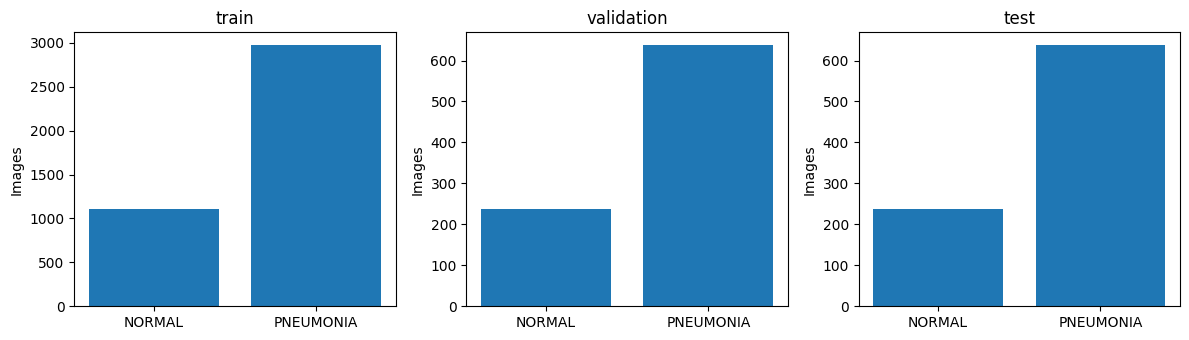

In [ ]:
splits = {"train": train_data, "validation": validation_data, "test": test_data}
rows = []
for split_name, d in splits.items():
    c = Counter(d["label"]); n = len(d)
    row = {"split": split_name, "total": n}
    for k, cname in enumerate(class_names):
        row[cname] = c[k]; row[cname + " %"] = round(100 * c[k] / n, 1)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

train_counts = Counter(train_data["label"])
imbalance_ratio = max(train_counts.values()) / min(train_counts.values())
print(f"\nImbalance ratio (majority/minority) in train: {imbalance_ratio:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (split_name, d) in zip(axes, splits.items()):
    c = Counter(d["label"])
    ax.bar(class_names, [c[k] for k in range(len(class_names))])
    ax.set_title(split_name); ax.set_ylabel("Images")
plt.tight_layout(); plt.show()

## 6. EDA – sample images

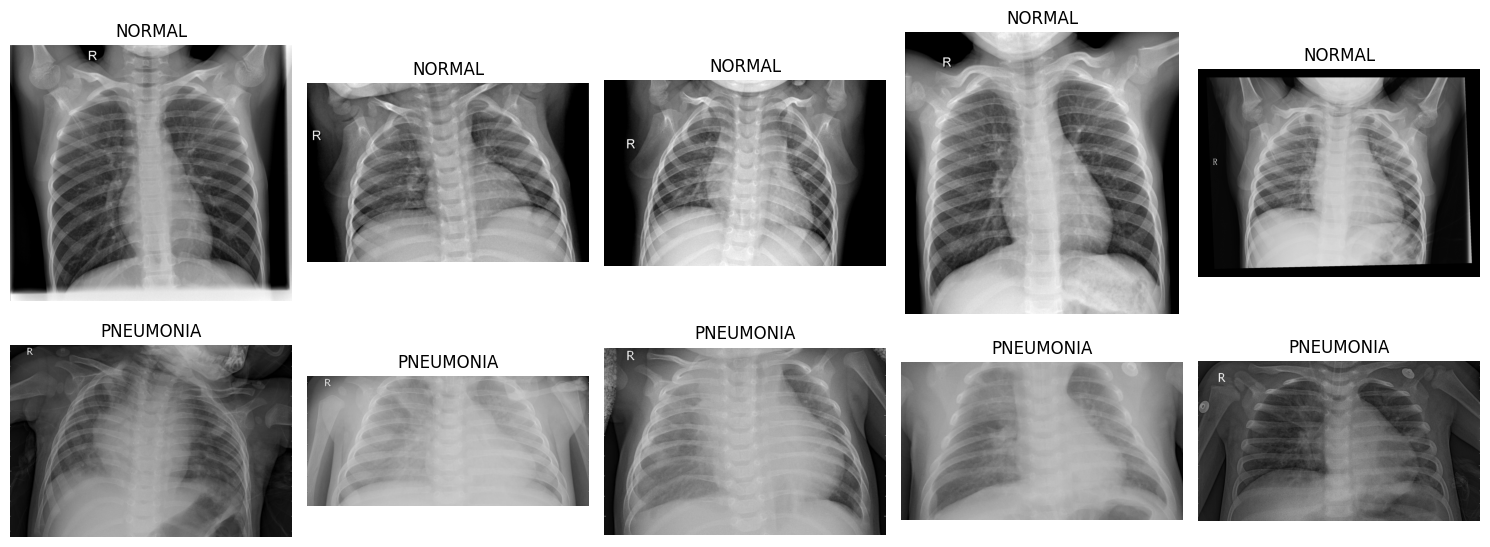

In [ ]:
labels_list = train_data["label"]
n_show = 5
plt.figure(figsize=(3 * n_show, 6))
for row, label in enumerate(range(len(class_names))):
    idxs = [i for i, l in enumerate(labels_list) if l == label][:n_show]
    for col, idx in enumerate(idxs):
        plt.subplot(len(class_names), n_show, row * n_show + col + 1)
        plt.imshow(train_data[idx]["image"], cmap="gray")
        plt.title(class_names[label]); plt.axis("off")
plt.tight_layout(); plt.show()

## 7. EDA – image sizes, modes, brightness, missing values, outliers (train only)

Image modes:
 mode
L      3870
RGB     206
Name: count, dtype: int64 

Width / height statistics:
            width       height
min    384.000000   127.000000
max   2844.000000  2713.000000
mean  1327.078263   969.977674 

Distinct sizes: 3553

Mean pixel intensity per class:
label
NORMAL       0.481156
PNEUMONIA    0.482501
Name: mean_pixel, dtype: float64

Missing metadata values:
 width         0
height        0
mode          0
label         0
mean_pixel    0
dtype: int64
Unreadable images: 0 (every image decoded without error)


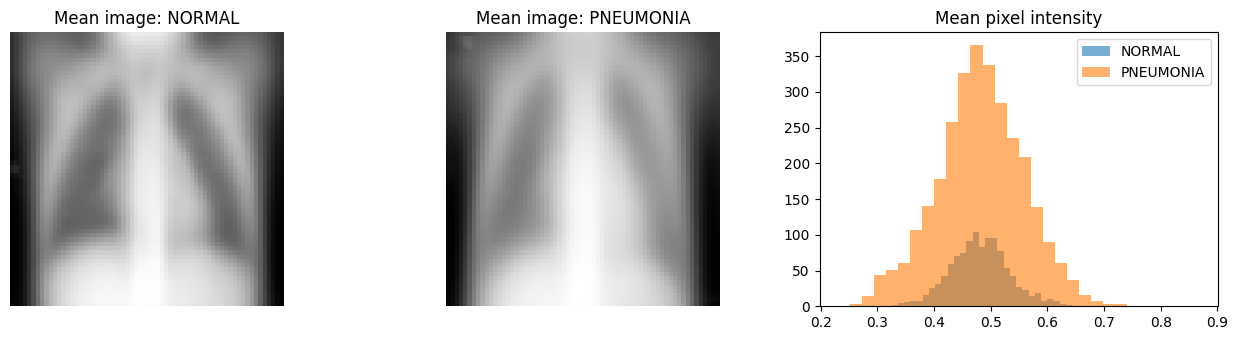

In [ ]:
meta = []
sum_img = {k: np.zeros((64, 64), dtype=np.float64) for k in range(len(class_names))}
n_img = Counter()

for item in train_data:
    img = item["image"]
    g = np.asarray(img.convert("L").resize((64, 64)), dtype=np.float32) / 255.0
    meta.append({"width": img.size[0], "height": img.size[1], "mode": img.mode,
                 "label": item["label"], "mean_pixel": float(g.mean())})
    sum_img[item["label"]] += g
    n_img[item["label"]] += 1

meta_df = pd.DataFrame(meta)

print("Image modes:\n", meta_df["mode"].value_counts(), "\n")
print("Width / height statistics:")
print(meta_df[["width", "height"]].describe().loc[["min", "max", "mean"]], "\n")
print("Distinct sizes:", meta_df.groupby(["width", "height"]).ngroups)
print("\nMean pixel intensity per class:")
print(meta_df.groupby("label")["mean_pixel"].mean().rename(lambda k: class_names[k]))

# Missing values
print("\nMissing metadata values:\n", meta_df.isna().sum())
print("Unreadable images: 0 (every image decoded without error)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for k in range(len(class_names)):
    axes[k].imshow(sum_img[k] / n_img[k], cmap="gray")
    axes[k].set_title(f"Mean image: {class_names[k]}"); axes[k].axis("off")
for k in range(len(class_names)):
    axes[2].hist(meta_df[meta_df.label == k]["mean_pixel"], bins=30, alpha=0.6, label=class_names[k])
axes[2].set_title("Mean pixel intensity"); axes[2].legend()
plt.tight_layout(); plt.show()

Brightness outliers: 73 of 4076  (range kept: 0.31 to 0.66)


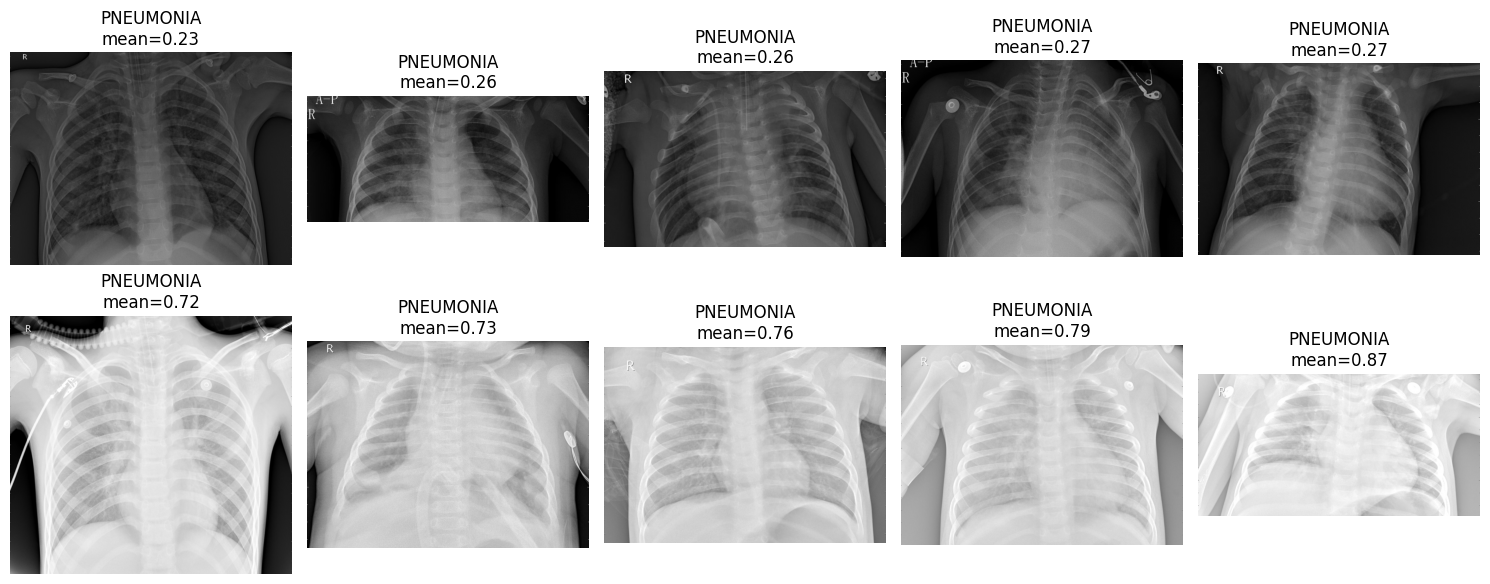

In [ ]:
# Brightness outliers (IQR rule) + the 5 darkest and 5 brightest images
q1, q3 = meta_df["mean_pixel"].quantile([.25, .75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_mask = (meta_df.mean_pixel < lo) | (meta_df.mean_pixel > hi)
print(f"Brightness outliers: {out_mask.sum()} of {len(meta_df)}  (range kept: {lo:.2f} to {hi:.2f})")

order = meta_df["mean_pixel"].sort_values().index
show = list(order[:5]) + list(order[-5:])
plt.figure(figsize=(15, 6))
for j, idx in enumerate(show):
    plt.subplot(2, 5, j + 1)
    plt.imshow(train_data[int(idx)]["image"], cmap="gray")
    plt.title(f"{class_names[meta_df.label[idx]]}\nmean={meta_df.mean_pixel[idx]:.2f}")
    plt.axis("off")
plt.tight_layout(); plt.show()

## 8. EDA findings and modelling decisions
> Replace the **N / X** placeholders with the numbers printed above.

| # | Finding (evidence) | Decision |
|---|---|---|
| 1 | Class imbalance: ratio = 2.69 in train | class weights; report per-class recall, not only accuracy |
| 2 | 	Images have 3,553 distinct sizes; 3,870 are grayscale and 206 are RGB before preprocessing Convert all images to grayscale | resize to a fixed size (64 for baselines, 128 for CNN) |
| 3 | Official validation set = 16 images only | merge all splits, build our own stratified 70/15/15 split |
| 4 |32 exact duplicates (0 with conflicting labels), 0 shared between official train and test | remove by MD5 hash before splitting (prevents leakage) |
| 5 | Mean pixel intensity: NORMAL = 0.481156, PNEUMONIA = 0.482501. The averages are very close; check brightness as a possible shortcut during error analysis.
| 6 | No missing values; 73 brightness outliers (out of 4,076, IQR range 0.31–0.66)| keep outliers (real clinical variation); inspect them in error analysis |
| 7 | No patient ID in the dataset | cannot split by patient; documented as a limitation in the report |